In [ ]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pda
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

In [3]:
# 도미
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [5]:
length = bream_length + smelt_length
weight = bream_weight + smelt_weight

data = [[l,w] for l,w in zip(length,weight)]
label = [1]*35 + [0]*14

train_data, test_data, train_label, test_label = train_test_split(data,label,stratify=label,test_size=0.2)


In [9]:
clf = KNeighborsClassifier()
clf.fit(train_data, train_label)
result = clf.predict(test_data)
# score = clf.score(test_data, test_label)
score = metrics.accuracy_score(result, test_label)
print('정답률: ', score)

정답률:  1.0


In [34]:
result2 = clf.predict([[29.5,300]])
print('예측생선: ', result2)

if result2 == 1:
    print('품종: ', '도미')
elif result2 == 0:
    print('품종: ', '빙어')



result3 = clf.predict([[25,150]])
print('예측생선: ', result3)

distances, indexes = clf.kneighbors([[25,150]])
print(distances, indexes)

예측생선:  [1]
품종:  도미
예측생선:  [0]
[[ 92.00086956 130.48375378 130.73859415 137.17988191 138.32150953]] [[22 33  9 23  6]]


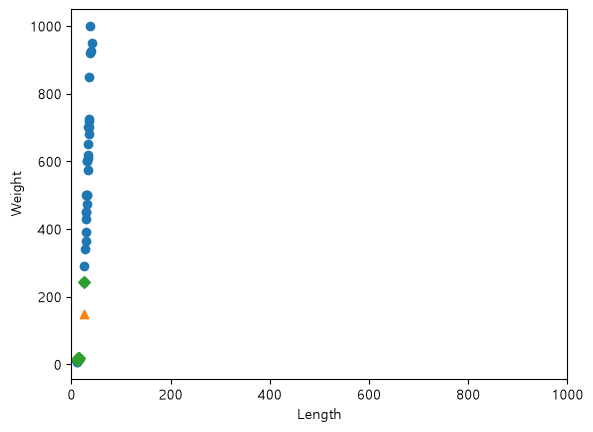

In [38]:
# plt.scatter(bream_length,bream_weight)
# plt.scatter(smelt_length,smelt_weight)
train_data = np.array(train_data)
plt.scatter(train_data[:,0], train_data[:,1])
plt.scatter(25,150,marker='^')
plt.scatter(train_data[indexes,0], train_data[indexes,1], marker='D')
#plt.scatter(29.5,330,marker='*')

plt.xlim(0,1000)
plt.xlabel('Length')
plt.ylabel('Weight')
plt.show()

In [70]:
mean = np.mean(data, axis=0) # 행 기준으로 산술평균
std = np.std(data, axis=0)   # 행 기준으로 표준편차

train_scaled = (data-mean)/std
new_fish = ([25,150]-mean)/std
new_fish

array([-0.20271784, -0.90677444])

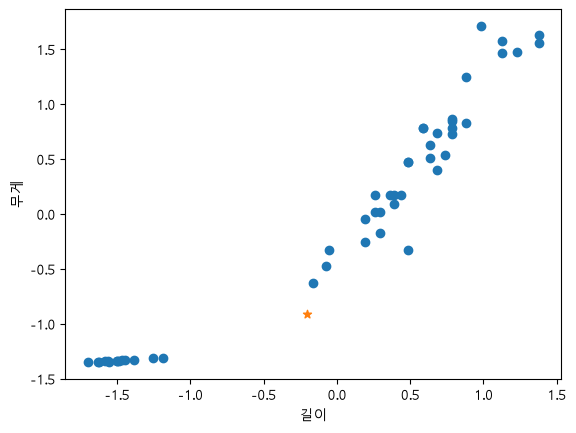

In [71]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_fish[0], new_fish[1], marker ='*')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [62]:

train_data, test_data, train_label, test_label = train_test_split(train_scaled,label)

In [ ]:
train_scaled = (data-mean)/std

distances,indexes = clf.kneighbors([new_fish])

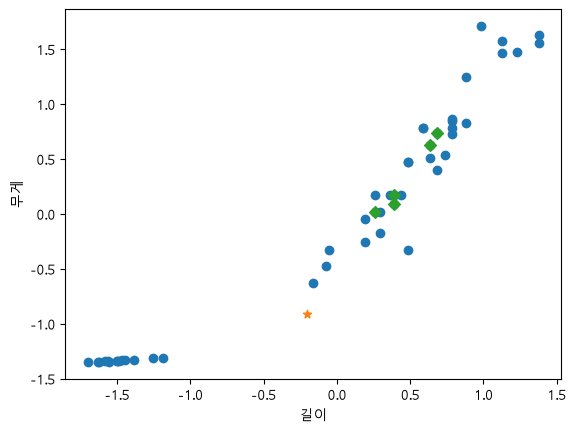

In [72]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_fish[0], new_fish[1], marker ='*')
plt.scatter(train_scaled[indexes, 0], train_scaled[indexes, 1], marker='D')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()